# Allow smoothness to vary across a predictor

A single roughness penalty can oversmooth an irregular region or undersmooth a quiet one. Adaptive smoothing lets the penalty strength vary along the predictor while retaining a smooth fitted function.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from nampy.gam import GAM

rng=np.random.default_rng(109)


## Generate a response with changing roughness

The left half is smooth; the right half has additional oscillation. Both fits receive the same basis dimension, rows, and REML criterion.

In [2]:
x=rng.uniform(0,1,700)
def truth(x):return np.sin(2*np.pi*x)+np.maximum(x-.5,0)*2*np.sin(18*np.pi*x)
data=pd.DataFrame({"x":x,"y":truth(x)+rng.normal(0,.15,len(x))})
train,test=train_test_split(data,test_size=.25,random_state=109)
models={"Ordinary":GAM(formula="y ~ s(x,bs='ps',k=32)",optimize_smoothing=True,smoothing_method="reml").fit(train),
        "Adaptive":GAM(formula="y ~ s(x,bs='ad',k=32,m=5)",optimize_smoothing=True,smoothing_method="reml").fit(train)}

## Compare the full curve and irregular region

Adaptive smoothing is an additional modeling choice, not a guarantee of lower test error. The close-up shows which features each fitted curve preserves.

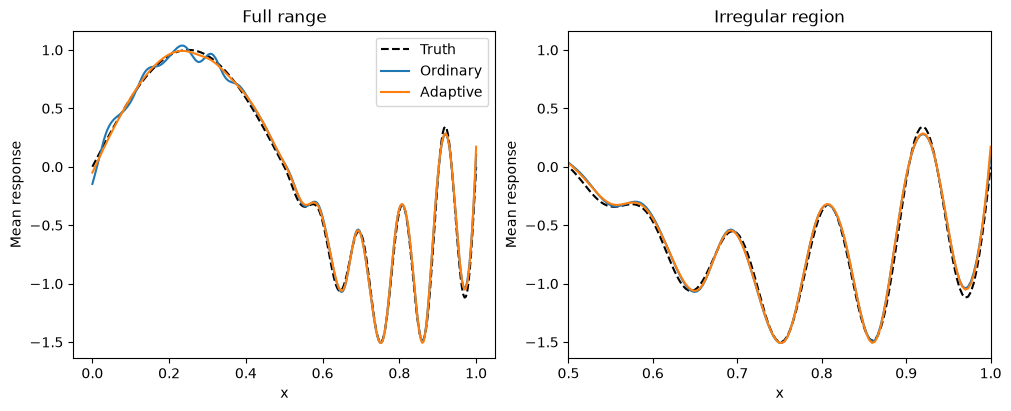

Model,Test RMSE
Ordinary,0.139
Adaptive,0.137


In [3]:
grid=pd.DataFrame({"x":np.linspace(0,1,300)})
figure,axes=plt.subplots(1,2,figsize=(10,4),constrained_layout=True)
for axis in axes:
    axis.plot(grid.x,truth(grid.x),"k--",label="Truth")
    for name,model in models.items():axis.plot(grid.x,model.predict(grid),label=name)
    axis.set(xlabel="x",ylabel="Mean response")
axes[0].set_title("Full range")
axes[1].set(xlim=(.5,1),title="Irregular region")
axes[0].legend()
plt.show()
plt.close(figure)
pd.DataFrame([{"Model":name,"Test RMSE":mean_squared_error(test.y,m.predict(test))**.5} for name,m in models.items()]).style.hide(axis="index").format({"Test RMSE":"{:.3f}"})

Test RMSE is 0.139 for the ordinary smooth and 0.137 for the adaptive smooth. The small difference should be read alongside the close-up; adaptive smoothing offers flexibility, but the ordinary fit already captures much of this pattern.